# 1. Data

122 respondents rated the same 20 messenger bags on a 1-5 scale ("definitely would not buy" to "definitely would buy"). They rated them twice: first online, then offline. Each bag is described by 6 attributes.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import load_data, encode, all_profiles, LEVELS

design, online, offline = load_data()
X = encode(design)
print(online.shape, offline.shape)
design.head()

(122, 20) (122, 20)


,exterior,size,price,strap_pad,pocket,interior
0,1,1,3,1,2,1
1,4,1,2,2,2,2
2,3,1,1,2,1,2
3,2,1,3,2,1,1
4,3,2,3,1,2,3


## Design

In [2]:
for a in design.columns:
    print(a, design[a].value_counts().sort_index().tolist())

exterior [4, 4, 6, 6]
size [10, 10]
price [6, 4, 6, 4]
strap_pad [10, 10]
pocket [10, 10]
interior [6, 6, 8]


In [3]:
# correlations between columns of different attributes
corr = X.corr()
attr = [c.split("_")[0] for c in X.columns]
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(X.columns) for j, b in enumerate(X.columns) if i < j and attr[i] != attr[j]]
print("max abs correlation between attributes:", round(max(abs(p[2]) for p in pairs), 2))
print("rank of design matrix:", np.linalg.matrix_rank(np.column_stack([np.ones(20), X])))
print("number of possible bags:", len(all_profiles()))

max abs correlation between attributes: 0.18
rank of design matrix: 10
number of possible bags: 384


The design is not perfectly balanced (e.g. price levels appear 6, 4, 6, 4 times), but attributes are close to orthogonal and all 10 parameters are identified. Each respondent gives 20 ratings for 10 parameters, so individual-level estimates will be noisy.

## Ratings

In [4]:
print("values outside 1..5 or not integer:")
for name, r in [("online", online), ("offline", offline)]:
    bad = np.argwhere((r % 1 != 0) | (r < 1) | (r > 5))
    print(name, [(i, j, r[i, j]) for i, j in bad])

values outside 1..5 or not integer:
online []
offline [(np.int64(81), np.int64(15), np.float64(2.5))]


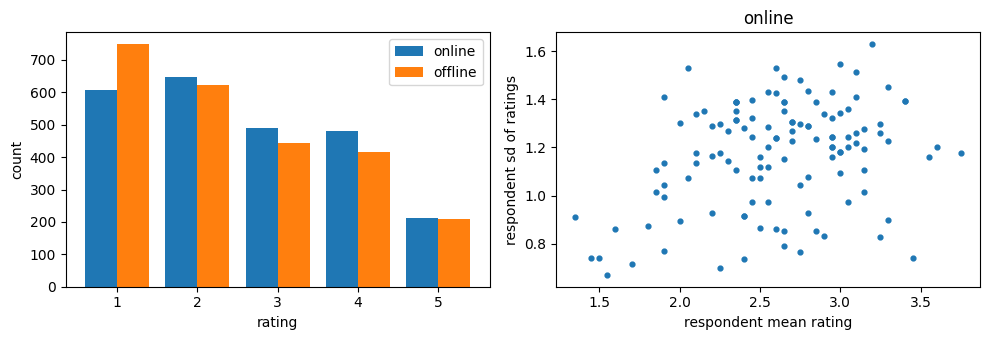

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
bins = np.arange(0.5, 6, 1)
ax[0].hist([online.ravel(), offline.ravel()], bins=bins, label=["online", "offline"])
ax[0].set_xlabel("rating")
ax[0].set_ylabel("count")
ax[0].legend()
ax[1].scatter(online.mean(1), online.std(1), s=12)
ax[1].set_xlabel("respondent mean rating")
ax[1].set_ylabel("respondent sd of ratings")
ax[1].set_title("online")
plt.tight_layout()
plt.show()

In [6]:
summary = pd.DataFrame({
    "online": [online.mean(), online.std(), (online >= 3).mean(), (online.std(1) < 0.5).sum()],
    "offline": [offline.mean(), offline.std(), (offline >= 3).mean(), (offline.std(1) < 0.5).sum()],
}, index=["mean", "sd", "share >= 3", "respondents with sd < 0.5"])
summary.round(2)

,online,offline
mean,2.61,2.47
sd,1.29,1.31
share >= 3,0.49,0.44
respondents with sd < 0.5,0.00,1.00


In [8]:
# how much of the variance is between respondents vs within
for name, r in [("online", online), ("offline", offline)]:
    between = r.mean(1).var()
    total = r.var()
    print(f"{name}: share of variance from respondent means = {between / total:.2f}")

online: share of variance from respondent means = 0.14
offline: share of variance from respondent means = 0.15


## Online vs offline for the same person

median correlation: 0.52
quartiles: [0.33 0.7 ]


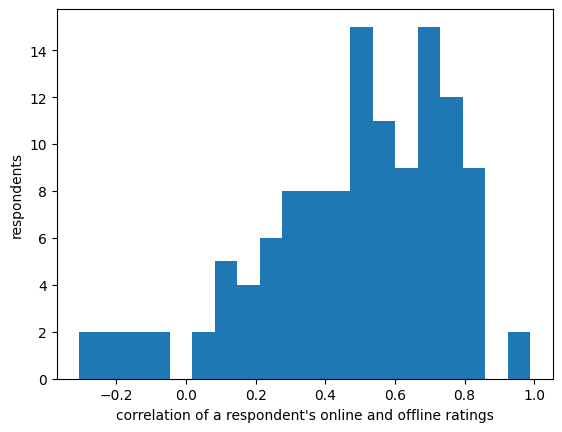

In [9]:
corrs = np.array([np.corrcoef(online[i], offline[i])[0, 1] for i in range(len(online))])
print("median correlation:", np.nanmedian(corrs).round(2))
print("quartiles:", np.nanpercentile(corrs, [25, 75]).round(2))
plt.hist(corrs[~np.isnan(corrs)], bins=20)
plt.xlabel("correlation of a respondent's online and offline ratings")
plt.ylabel("respondents")
plt.show()

The same people rate the same bags quite differently the second time (median correlation 0.52). In this project the online ratings are the main data and the offline ratings are used later to check whether segments replicate.